# Evaluasi & Analisis Hasil Simulasi Penjadwalan Cloudlet Menggunakan CloudSim Plus & Algoritma TOPSIS
**Strategi Optimasi Komputasi Awan (SOKA) - Kelompok 5**

Notebook ini menyajikan analisis data komprehensif dari hasil eksekusi simulasi **CloudSim Plus 8.0.0** dengan algoritma multi-kriteria **TOPSIS (Technique for Order Preference by Similarity to Ideal Solution)** pada workload skala masif **Google Cloud Jobs (GoCJ)**.

### 1. Spesifikasi Arsitektur Simulasi CloudSim Plus
- **Hierarki Data Center:** 2 Datacenter Fisik (DC 1: Host 0–3, DC 2: Host 4–7).
- **Physical Host Fisik (Homogen):** 8 Physical Host homogen dengan spesifikasi masing-masing:
  - **24 Core CPU** @ 10.000 MIPS (Total 192 Physical Core)
  - **64 GB RAM** / 65.536 MB (Total 512 GB RAM)
  - **2 TB Storage** (Total 16 TB Storage)
  - **10 Gbps Bandwidth**
  - Kebijakan Alokasi: `VmSchedulerSpaceShared` (Core dedicated tanpa preemption)
- **Virtual Machine (Heterogen):** 80 VM heterogen terdistribusi merata (10 VM per Host):
  - **Small (32 VM):** 1 vCPU, 1.000 MIPS, RAM 2 GB, Tarif $0.05/jam
  - **Medium (32 VM):** 2 vCPU, 2.500 MIPS, RAM 4 GB, Tarif $0.12/jam
  - **Large (16 VM):** 4 vCPU, 5.000 MIPS, RAM 8 GB, Tarif $0.25/jam
  - Tarif Sewa Agregat Infrastruktur: **$9.44 per jam**

### 2. Karakteristik Workload Google Cloud Jobs (GoCJ)
- **Independent Batch Tasks (Bag-of-Tasks):** Seluruh task bersifat independen tanpa precedence barrier atau dependency graph.
- **Kolom SLA adalah Service Level Agreement (Tingkat Prioritas):** SLA {1, 2, 3} merepresentasikan level of priority (1 = Low ~18%, 2 = Medium ~50%, 3 = High ~32%), **BUKAN dependensi task**.
- **Skala Pengujian:** 1.000 hingga 10.000 tasks (10 variasi ukuran), dieksekusi masing-masing **3 kali repeated runs** untuk menguji konsistensi statistik (Mean ± Std Dev).

### Asumsi model dan koreksi data
- Arrival time diterapkan pada simulasi dan prediksi antrean per PE. Cloudlet satu PE dapat berjalan paralel: Small 1, Medium 2, Large 4.
- Skor TOPSIS seri diselesaikan dengan jumlah task teralokasi paling sedikit, lalu indeks VM terkecil. Skor TOPSIS yang lebih rendah tetap tidak dipilih demi pemerataan.
- Makespan adalah timestamp selesai terakhir sejak awal simulasi. BusyTime menjumlahkan durasi seluruh task termasuk I/O; task paralel tetap dijumlahkan. DI memakai BusyTime seluruh 80 VM, termasuk VM tanpa task.
- I/O 50–500 MB memakai satuan desimal dan dimodelkan sebagai tambahan durasi CPU tanpa contention jaringan. Biaya mengikuti `ceil(BusyTime / 3600) × tarif VM`, bukan tagihan aktual penyedia cloud.
- CSV wajib sesuai skala tanpa fallback. SLA adalah metadata, belum menjadi kriteria atau aturan prioritas TOPSIS.
- SLA 4 pada baris 4986 dataset 5.000 task diimputasi menjadi SLA 2. Dasar dan nilai awal tercatat pada [catatan koreksi data](../gocj_dataset/DATA_CORRECTIONS.md).
- Mean dan standar deviasi sampel (`ddof=1`) dihitung dari tiga run. Alokasi VM berasal dari skala 10.000 task, run ketiga.


In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

# Menemukan direktori docs dan file CSV hasil simulasi CloudSim Plus
def find_csv_path(filename):
    candidates = [
        os.path.join('docs', filename),
        os.path.join('..', 'docs', filename),
        os.path.join('task-4', 'docs', filename),
        filename
    ]
    for c in candidates:
        if os.path.exists(c):
            return os.path.abspath(c)
    raise FileNotFoundError(f'File {filename} tidak ditemukan.')

metrics_csv = find_csv_path('cloudsim_metrics.csv')
vm_csv = find_csv_path('cloudsim_vm_allocation.csv')

df_metrics = pd.read_csv(metrics_csv)
df_vm = pd.read_csv(vm_csv)

print(f"[INFO] Data metrik berhasil dimuat: {len(df_metrics)} baris pengujian (10 skala × 3 runs).")
print(f"[INFO] Data alokasi VM berhasil dimuat: {len(df_vm)} Virtual Machines pada skala 10.000 task.")

[INFO] Data metrik berhasil dimuat: 30 baris pengujian (10 skala × 3 runs).
[INFO] Data alokasi VM berhasil dimuat: 80 Virtual Machines pada skala 10.000 task.


In [2]:
# Tabel Ringkasan Statistik Hasil Evaluasi Multi-Run (Mean ± Std Dev)
agg_summary = df_metrics.groupby('Tasks').agg({
    'Makespan_s': ['mean', 'std'],
    'TotalCost_USD': ['mean', 'std'],
    'DI': ['mean', 'std'],
    'Runtime_ms': ['mean', 'std']
}).reset_index()

summary_display = pd.DataFrame({
    'Tasks': agg_summary['Tasks'],
    'Makespan (s)': agg_summary.apply(lambda r: f"{r[('Makespan_s', 'mean')]:.2f} ± {r[('Makespan_s', 'std')]:.2f}", axis=1),
    'Total Cost ($)': agg_summary.apply(lambda r: f"{r[('TotalCost_USD', 'mean')]:.2f} ± {r[('TotalCost_USD', 'std')]:.2f}", axis=1),
    'DI (Imbalance)': agg_summary.apply(lambda r: f"{r[('DI', 'mean')]:.4f} ± {r[('DI', 'std')]:.4f}", axis=1),
    'Runtime (ms)': agg_summary.apply(lambda r: f"{r[('Runtime_ms', 'mean')]:.2f} ± {r[('Runtime_ms', 'std')]:.2f}", axis=1)
})

print("=== RINGKASAN HASIL EVALUASI CLOUDSIM PLUS (MEAN ± STD DEV, 3 REPEATED RUNS) ===")
summary_display

=== RINGKASAN HASIL EVALUASI CLOUDSIM PLUS (MEAN ± STD DEV, 3 REPEATED RUNS) ===


,Tasks,Makespan (s),Total Cost ($),DI (Imbalance),Runtime (ms)
0,1000,1795.32 ± 0.50,9.44 ± 0.00,1.8791 ± 0.1453,27.36 ± 13.83
1,2000,3057.22 ± 7.00,9.44 ± 0.00,1.6819 ± 0.0824,37.45 ± 6.93
2,3000,4090.30 ± 1.30,10.12 ± 0.07,1.4266 ± 0.0413,31.10 ± 8.98
3,4000,4622.44 ± 1.51,13.28 ± 0.00,1.4659 ± 0.0223,33.48 ± 0.35
4,5000,5188.17 ± 1.32,13.28 ± 0.00,1.4410 ± 0.0228,36.97 ± 1.94
5,6000,6200.55 ± 1.41,14.20 ± 0.14,1.3660 ± 0.0547,56.10 ± 3.93
6,7000,16403.96 ± 0.78,17.57 ± 0.17,1.8876 ± 0.0490,53.61 ± 6.02
7,8000,18789.69 ± 1.08,20.78 ± 0.28,2.0017 ± 0.0641,69.51 ± 2.86
8,9000,21023.49 ± 0.47,22.36 ± 0.18,1.9103 ± 0.0320,72.63 ± 11.55
9,10000,23118.20 ± 0.69,23.20 ± 0.18,1.8765 ± 0.0228,85.60 ± 18.93


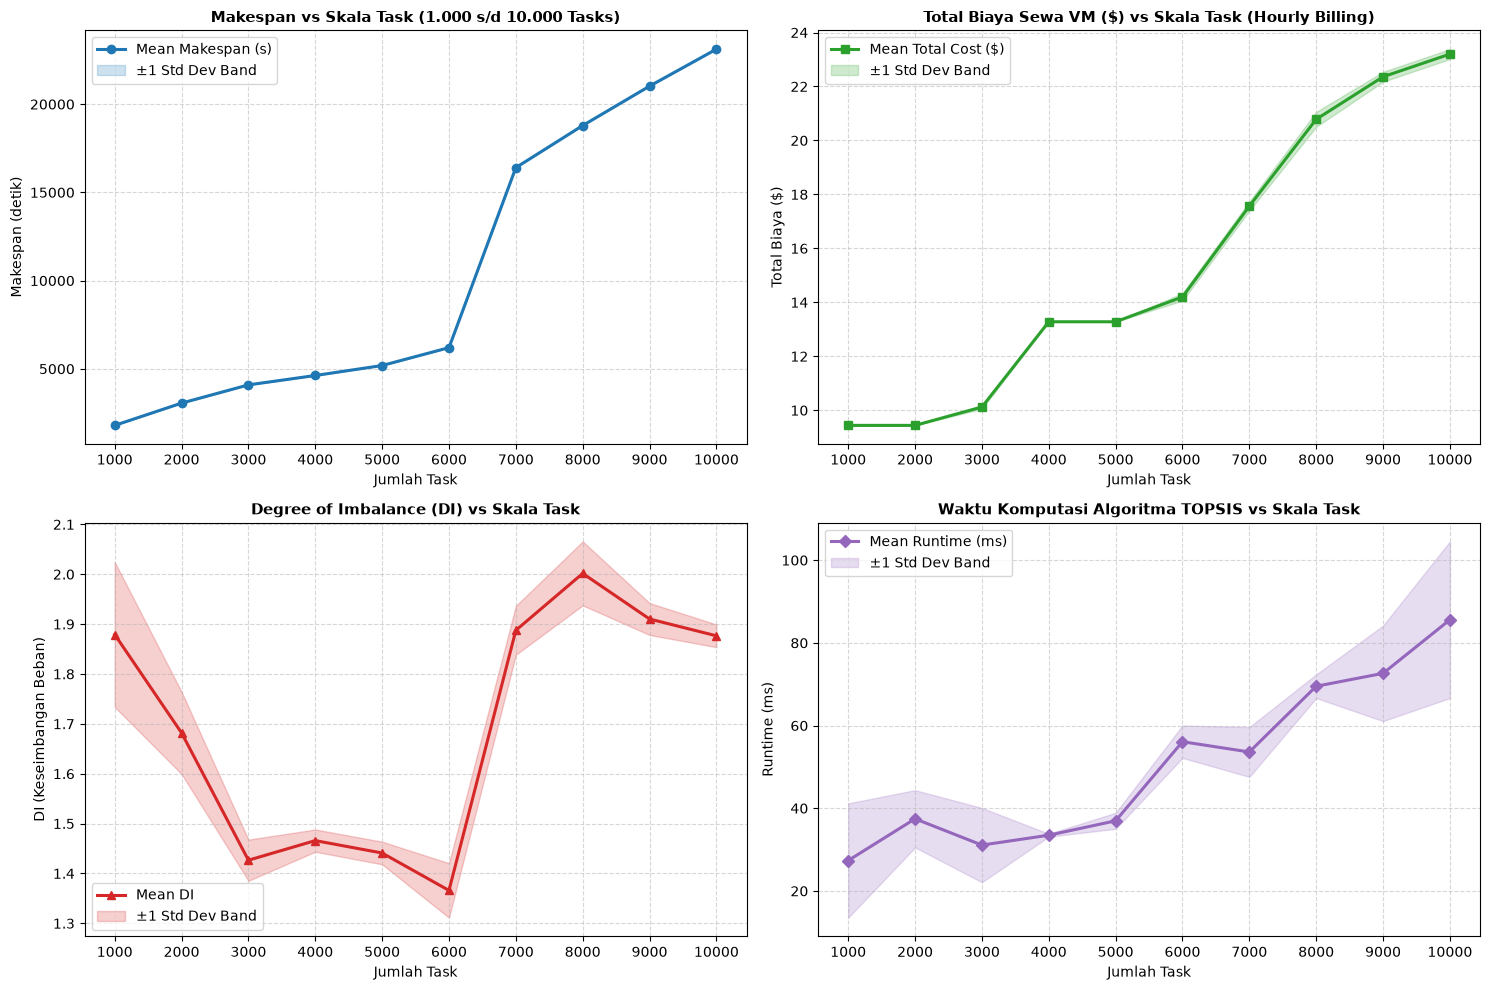

In [3]:
# Visualisasi 1: 4 Subplot Metrik Evaluasi dengan Error Band (Makespan, Total Cost, DI, Runtime)
tasks = agg_summary['Tasks'].values
m_mean = agg_summary[('Makespan_s', 'mean')].values
m_std = agg_summary[('Makespan_s', 'std')].fillna(0).values

c_mean = agg_summary[('TotalCost_USD', 'mean')].values
c_std = agg_summary[('TotalCost_USD', 'std')].fillna(0).values

di_mean = agg_summary[('DI', 'mean')].values
di_std = agg_summary[('DI', 'std')].fillna(0).values

rt_mean = agg_summary[('Runtime_ms', 'mean')].values
rt_std = agg_summary[('Runtime_ms', 'std')].fillna(0).values

fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# 1. Makespan
axes[0, 0].plot(tasks, m_mean, marker='o', color='#1f77b4', linewidth=2.2, label='Mean Makespan (s)')
axes[0, 0].fill_between(tasks, m_mean - m_std, m_mean + m_std, color='#1f77b4', alpha=0.22, label='±1 Std Dev Band')
axes[0, 0].set_title("Makespan vs Skala Task (1.000 s/d 10.000 Tasks)", fontsize=11, fontweight='bold')
axes[0, 0].set_xlabel("Jumlah Task")
axes[0, 0].set_ylabel("Makespan (detik)")
axes[0, 0].set_xticks(tasks)
axes[0, 0].grid(True, linestyle='--', alpha=0.5)
axes[0, 0].legend()

# 2. Total Cost
axes[0, 1].plot(tasks, c_mean, marker='s', color='#2ca02c', linewidth=2.2, label='Mean Total Cost ($)')
axes[0, 1].fill_between(tasks, c_mean - c_std, c_mean + c_std, color='#2ca02c', alpha=0.22, label='±1 Std Dev Band')
axes[0, 1].set_title("Total Biaya Sewa VM ($) vs Skala Task (Hourly Billing)", fontsize=11, fontweight='bold')
axes[0, 1].set_xlabel("Jumlah Task")
axes[0, 1].set_ylabel("Total Biaya ($)")
axes[0, 1].set_xticks(tasks)
axes[0, 1].grid(True, linestyle='--', alpha=0.5)
axes[0, 1].legend()

# 3. Degree of Imbalance
axes[1, 0].plot(tasks, di_mean, marker='^', color='#d62728', linewidth=2.2, label='Mean DI')
axes[1, 0].fill_between(tasks, di_mean - di_std, di_mean + di_std, color='#d62728', alpha=0.22, label='±1 Std Dev Band')
axes[1, 0].set_title("Degree of Imbalance (DI) vs Skala Task", fontsize=11, fontweight='bold')
axes[1, 0].set_xlabel("Jumlah Task")
axes[1, 0].set_ylabel("DI (Keseimbangan Beban)")
axes[1, 0].set_xticks(tasks)
axes[1, 0].grid(True, linestyle='--', alpha=0.5)
axes[1, 0].legend()

# 4. Runtime TOPSIS
axes[1, 1].plot(tasks, rt_mean, marker='D', color='#9467bd', linewidth=2.2, label='Mean Runtime (ms)')
axes[1, 1].fill_between(tasks, rt_mean - rt_std, rt_mean + rt_std, color='#9467bd', alpha=0.22, label='±1 Std Dev Band')
axes[1, 1].set_title("Waktu Komputasi Algoritma TOPSIS vs Skala Task", fontsize=11, fontweight='bold')
axes[1, 1].set_xlabel("Jumlah Task")
axes[1, 1].set_ylabel("Runtime (ms)")
axes[1, 1].set_xticks(tasks)
axes[1, 1].grid(True, linestyle='--', alpha=0.5)
axes[1, 1].legend()

plt.tight_layout()
plt.show()

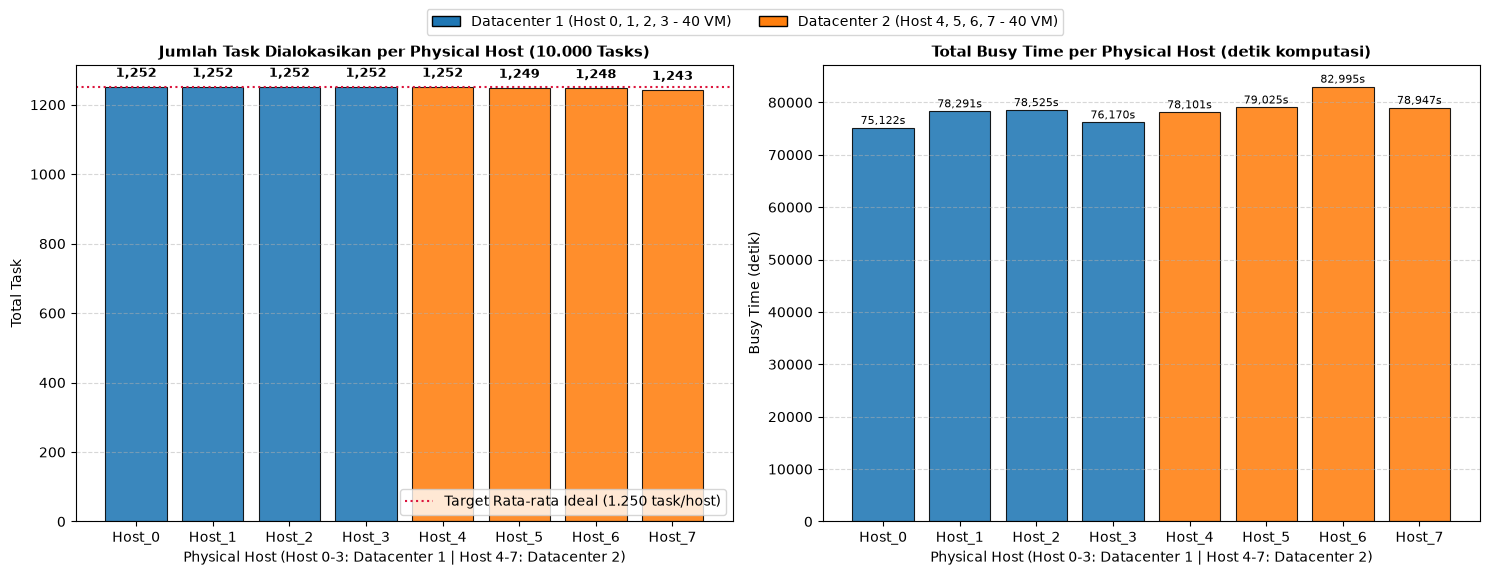

In [4]:
# Visualisasi 2: Distribusi Alokasi per Physical Host (Membuktikan Tidak Ada Host Menganggur)
host_agg = df_vm.groupby(['DatacenterId', 'HostId']).agg({
    'TaskCount': 'sum',
    'BusyTime_s': 'sum'
}).reset_index()

hosts = host_agg['HostId'].values
host_tasks = host_agg['TaskCount'].values
host_busy = host_agg['BusyTime_s'].values
dc_colors = ['#1f77b4' if dc == 'DC_1' else '#ff7f0e' for dc in host_agg['DatacenterId']]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5.5))

# Subplot A: Total Task per Host
bars1 = ax1.bar(hosts, host_tasks, color=dc_colors, alpha=0.88, edgecolor='black', linewidth=0.8)
ax1.set_title("Jumlah Task Dialokasikan per Physical Host (10.000 Tasks)", fontsize=11, fontweight='bold')
ax1.set_xlabel("Physical Host (Host 0-3: Datacenter 1 | Host 4-7: Datacenter 2)")
ax1.set_ylabel("Total Task")
ax1.axhline(y=10000 / 8, color='crimson', linestyle=':', label='Target Rata-rata Ideal (1.250 task/host)')
ax1.grid(True, linestyle='--', alpha=0.5, axis='y')
for bar in bars1:
    h = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width() / 2.0, h + 20, f"{int(h):,}", ha='center', va='bottom', fontsize=9, fontweight='bold')
ax1.legend(loc='lower right')

# Subplot B: Total Busy Time per Host
bars2 = ax2.bar(hosts, host_busy, color=dc_colors, alpha=0.88, edgecolor='black', linewidth=0.8)
ax2.set_title("Total Busy Time per Physical Host (detik komputasi)", fontsize=11, fontweight='bold')
ax2.set_xlabel("Physical Host (Host 0-3: Datacenter 1 | Host 4-7: Datacenter 2)")
ax2.set_ylabel("Busy Time (detik)")
ax2.grid(True, linestyle='--', alpha=0.5, axis='y')
for bar in bars2:
    h = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width() / 2.0, h + 250, f"{int(h):,}s", ha='center', va='bottom', fontsize=8)

legend_elements = [
    Patch(facecolor='#1f77b4', edgecolor='black', label='Datacenter 1 (Host 0, 1, 2, 3 - 40 VM)'),
    Patch(facecolor='#ff7f0e', edgecolor='black', label='Datacenter 2 (Host 4, 5, 6, 7 - 40 VM)')
]
fig.legend(handles=legend_elements, loc='upper center', bbox_to_anchor=(0.5, 1.05), ncol=2, frameon=True)

plt.tight_layout()
plt.show()

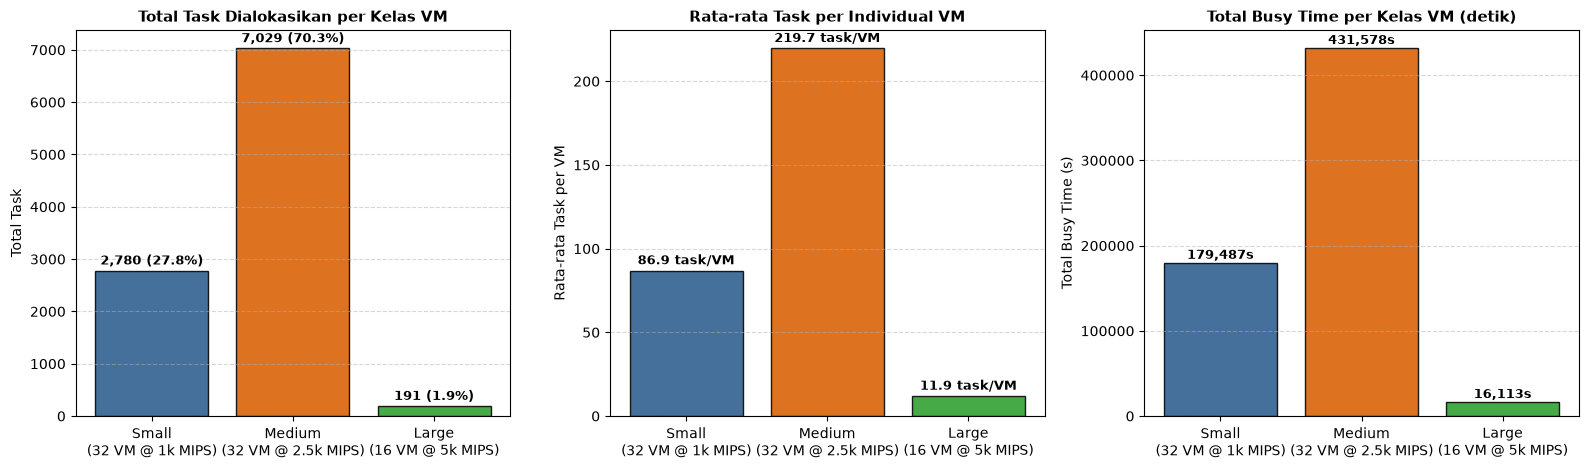

In [5]:
# Visualisasi 3: Analisis Pemanfaatan Berdasarkan 3 Kelas VM (Small, Medium, Large)
type_agg = df_vm.groupby('VmType').agg({
    'TaskCount': ['sum', 'mean'],
    'BusyTime_s': ['sum', 'mean'],
    'VmId': 'count'
}).loc[['Small', 'Medium', 'Large']]

labels = ['Small\n(32 VM @ 1k MIPS)', 'Medium\n(32 VM @ 2.5k MIPS)', 'Large\n(16 VM @ 5k MIPS)']
colors = ['#2b5c8f', '#d95f02', '#2ca02c']

fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))

# 1. Total Task per Kelas
bars1 = axes[0].bar(labels, type_agg['TaskCount']['sum'], color=colors, alpha=0.88, edgecolor='black')
axes[0].set_title("Total Task Dialokasikan per Kelas VM", fontsize=11, fontweight='bold')
axes[0].set_ylabel("Total Task")
axes[0].grid(True, linestyle='--', alpha=0.5, axis='y')
for bar in bars1:
    h = bar.get_height()
    axes[0].text(bar.get_x() + bar.get_width() / 2.0, h + 60, f"{int(h):,} ({h/10000*100:.1f}%)", ha='center', va='bottom', fontsize=9, fontweight='bold')

# 2. Rata-rata Task per Individual VM
bars2 = axes[1].bar(labels, type_agg['TaskCount']['mean'], color=colors, alpha=0.88, edgecolor='black')
axes[1].set_title("Rata-rata Task per Individual VM", fontsize=11, fontweight='bold')
axes[1].set_ylabel("Rata-rata Task per VM")
axes[1].grid(True, linestyle='--', alpha=0.5, axis='y')
for bar in bars2:
    h = bar.get_height()
    axes[1].text(bar.get_x() + bar.get_width() / 2.0, h + 2, f"{h:.1f} task/VM", ha='center', va='bottom', fontsize=9, fontweight='bold')

# 3. Total Busy Time per Kelas VM
bars3 = axes[2].bar(labels, type_agg['BusyTime_s']['sum'], color=colors, alpha=0.88, edgecolor='black')
axes[2].set_title("Total Busy Time per Kelas VM (detik)", fontsize=11, fontweight='bold')
axes[2].set_ylabel("Total Busy Time (s)")
axes[2].grid(True, linestyle='--', alpha=0.5, axis='y')
for bar in bars3:
    h = bar.get_height()
    axes[2].text(bar.get_x() + bar.get_width() / 2.0, h + 1500, f"{int(h):,}s", ha='center', va='bottom', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.show()

### 3. Diskusi Ilmiah & Kesimpulan Eksperimen

#### A. Formulasi Matematis Algoritma TOPSIS
Algoritma TOPSIS mengevaluasi matriks keputusan $X = [x_{ij}]_{m \times n}$ di mana setiap alternatif adalah kandidat Virtual Machine ($m = 80$ VM) dan setiap kriteria adalah fungsi objektif penjadwalan ($n = 2$: Completion Time dan Execution Cost):

1. **Normalisasi Vektor (Vector Normalization):**
   $$r_{ij} = \frac{x_{ij}}{\sqrt{\sum_{k=1}^{m} x_{kj}^2}}$$
2. **Matriks Ternormalisasi Terbobot (Weighted Normalized Matrix):**
   $$v_{ij} = w_j \cdot r_{ij}, \quad \text{dengan } w_{\text{time}} = 0.5, \; w_{\text{cost}} = 0.5$$
3. **Solusi Ideal Positif ($A^+$) dan Solusi Ideal Negatif ($A^-$):**
   Karena kedua kriteria merupakan *cost criteria* (semakin kecil waktu dan biaya, semakin baik):
   $$A^+ = \{\min_k v_{k1}, \min_k v_{k2}\}, \quad A^- = \{\max_k v_{k1}, \max_k v_{k2}\}$$
4. **Jarak Euclidean ke Solusi Ideal:**
   $$d_i^+ = \sqrt{\sum_{j=1}^{2} (v_{ij} - A_j^+)^2}, \quad d_i^- = \sqrt{\sum_{j=1}^{2} (v_{ij} - A_j^-)^2}$$
5. **Skor Kedekatan Relatif (Relative Closeness Coefficient):**
   $$C_i^* = \frac{d_i^-}{d_i^+ + d_i^- + 10^{-9}}$$
   Task dialokasikan ke VM dengan skor $C_i^*$ tertinggi (paling dekat dengan solusi ideal positif dan paling jauh dari solusi negatif).

#### B. Pemetaan Infrastruktur dan Beban Aktual
- Setiap host menampung tepat 10 VM dengan pemetaan deterministik. Hal ini menjamin penempatan VM yang transparan, tetapi tidak menjamin distribusi task merata atau host selalu sibuk.
- Distribusi task dan akumulasi durasi per host serta kelas VM dibaca langsung dari CSV hasil simulasi pada grafik di atas.
- DI menggunakan akumulasi durasi task, sehingga VM tanpa task tetap berkontribusi sebagai beban nol. DI tidak dinormalisasi terhadap jumlah PE.

#### C. Skalabilitas dan Konsistensi
- Nilai runtime serta variasi makespan, biaya, dan DI dihitung dari tiga repeated runs dengan seed I/O berbeda pada tabel ringkasan.
- Runtime bergantung pada mesin pengujian dan kondisi JVM. Tiga run menggambarkan variasi eksperimen ini, tanpa membuktikan optimalitas global atau konsistensi universal.
